In [1]:
from pathlib import Path
import numpy as np
import nibabel as nib
import pydicom
import os

/gpfs/home/kn2347/.conda/envs/autopet3_lesiontracer/lib/python3.10/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [4]:
from pathlib import Path
from datetime import datetime
import numpy as np
import nibabel as nib
import pydicom
import os
import SimpleITK as sitk


def _load_dicom_series(series_dir):
    series_dir = Path(series_dir)
    dicom_paths = sorted(series_dir.glob('*.dcm'))
    if not dicom_paths:
        raise FileNotFoundError(f'No DICOM files found in {series_dir}')

    datasets = [pydicom.dcmread(str(path)) for path in dicom_paths]
    first = datasets[0]
    orientation = np.asarray(first.ImageOrientationPatient, dtype=float)
    row_cosines = orientation[:3]
    col_cosines = orientation[3:]
    slice_cosines = np.cross(row_cosines, col_cosines)

    positions = np.array([np.asarray(ds.ImagePositionPatient, dtype=float) for ds in datasets])
    sort_order = np.argsort(positions @ slice_cosines)
    datasets = [datasets[index] for index in sort_order]
    positions = positions[sort_order]
    return datasets, row_cosines, col_cosines, slice_cosines, positions



def _affine_from_dicom_series(datasets, row_cosines, col_cosines, slice_cosines, positions):
    first = datasets[0]
    row_spacing, col_spacing = np.asarray(first.PixelSpacing, dtype=float)
    if len(datasets) > 1:
        slice_spacing = float(np.median(np.abs(np.diff(positions @ slice_cosines))))
    else:
        slice_spacing = float(getattr(first, 'SpacingBetweenSlices', getattr(first, 'SliceThickness', 1.0)))

    affine = np.eye(4, dtype=float)
    affine[:3, 0] = row_cosines * row_spacing
    affine[:3, 1] = col_cosines * col_spacing
    affine[:3, 2] = slice_cosines * slice_spacing
    affine[:3, 3] = np.asarray(first.ImagePositionPatient, dtype=float)
    return affine



def _parse_dicom_time(time_value):
    if time_value is None:
        return None
    text = str(time_value).strip()
    if not text:
        return None
    text = text.split('.')[0].zfill(6)[:6]
    return datetime.strptime(text, '%H%M%S')



def _pet_suv_factor_from_dicom_series(series_dir):
    series_dir = Path(series_dir)
    dicom_paths = sorted(series_dir.glob('*.dcm'))
    if not dicom_paths:
        raise FileNotFoundError(f'No DICOM files found in {series_dir}')

    first = pydicom.dcmread(str(dicom_paths[0]), stop_before_pixels=True)
    if not hasattr(first, 'RadiopharmaceuticalInformationSequence'):
        raise ValueError(f'Missing RadiopharmaceuticalInformationSequence in {series_dir}')

    rph = first.RadiopharmaceuticalInformationSequence[0]
    if not hasattr(first, 'PatientWeight'):
        raise ValueError(f'Missing PatientWeight in {series_dir}')
    if not hasattr(rph, 'RadionuclideTotalDose'):
        raise ValueError(f'Missing RadionuclideTotalDose in {series_dir}')
    if not hasattr(rph, 'RadionuclideHalfLife'):
        raise ValueError(f'Missing RadionuclideHalfLife in {series_dir}')

    scan_time = _parse_dicom_time(getattr(first, 'SeriesTime', None))
    injection_time = _parse_dicom_time(getattr(rph, 'RadiopharmaceuticalStartTime', None))
    if scan_time is None or injection_time is None:
        raise ValueError(f'Missing scan/injection time in {series_dir}')

    dt_seconds = (scan_time - injection_time).total_seconds()
    if dt_seconds < 0:
        dt_seconds += 24 * 3600

    half_life = float(rph.RadionuclideHalfLife)
    total_dose = float(rph.RadionuclideTotalDose)
    decay = np.exp(-np.log(2.0) * dt_seconds / half_life)
    injected_dose_atscan = total_dose * decay
    if injected_dose_atscan <= 0:
        raise ValueError(f'Computed non-positive injected dose for {series_dir}')

    return (float(first.PatientWeight) * 1e3) / injected_dose_atscan



def _series_to_nifti(series_dir):
    datasets, row_cosines, col_cosines, slice_cosines, positions = _load_dicom_series(series_dir)
    affine = _affine_from_dicom_series(datasets, row_cosines, col_cosines, slice_cosines, positions)
    volume = np.stack([dataset.pixel_array for dataset in datasets], axis=-1).astype(np.float32)
    nii = nib.Nifti1Image(volume, affine)
    nii.set_qform(nii.affine, code=1)
    nii.set_sform(nii.affine, code=1)
    return nii



def _sitk_from_dicom_series(series_dir):
    series_dir = Path(series_dir)
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(str(series_dir))
    if not dicom_names:
        raise FileNotFoundError(f'No DICOM files found in {series_dir}')
    reader.SetFileNames(dicom_names)
    return reader.Execute()



def _resample_moving_to_reference(moving_image, reference_image, interpolator=sitk.sitkLinear, default_value=0.0):
    resampler = sitk.ResampleImageFilter()
    resampler.SetReferenceImage(reference_image)
    resampler.SetInterpolator(interpolator)
    resampler.SetDefaultPixelValue(default_value)
    resampler.SetTransform(sitk.Transform())
    return resampler.Execute(moving_image)



def _sitk_to_nifti(image):
    array = sitk.GetArrayFromImage(image).transpose((2, 1, 0)).astype(np.float32)
    affine = np.array(image.GetDirection(), dtype=float).reshape(3, 3)
    affine = np.column_stack((affine * np.array(image.GetSpacing(), dtype=float), np.asarray(image.GetOrigin(), dtype=float)))
    affine = np.vstack((affine, [0.0, 0.0, 0.0, 1.0]))
    nii = nib.Nifti1Image(array, affine)
    nii.set_qform(nii.affine, code=1)
    nii.set_sform(nii.affine, code=1)
    return nii



def _nnunet_name(series_dir):
    series_name = Path(series_dir).name
    if '_ct_' in series_name:
        return f'{series_name.split("_ct_")[0]}_0000.nii.gz'
    if '_pt_' in series_name:
        return f'{series_name.split("_pt_")[0]}_0001.nii.gz'
    raise ValueError(f'Cannot infer nnUNet modality suffix from {series_name}')



def convert_nnunet_pair_from_dicoms(ct_series_dir, pt_series_dir, out_dir):
    out_dir = Path(out_dir)
    ct_path = out_dir / _nnunet_name(ct_series_dir)
    pt_path = out_dir / _nnunet_name(pt_series_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    ct_image = _sitk_from_dicom_series(ct_series_dir)
    pt_image = _sitk_from_dicom_series(pt_series_dir)
    pt_resampled = _resample_moving_to_reference(pt_image, ct_image, interpolator=sitk.sitkLinear, default_value=0.0)

    suv_factor = _pet_suv_factor_from_dicom_series(pt_series_dir)
    pt_array = sitk.GetArrayFromImage(pt_resampled).astype(np.float32) * suv_factor
    pt_array = np.clip(pt_array, 0.0, None)
    pt_resampled_suv = sitk.GetImageFromArray(pt_array)
    pt_resampled_suv.CopyInformation(ct_image)

    nib.save(_sitk_to_nifti(ct_image), str(ct_path))
    nib.save(_sitk_to_nifti(pt_resampled_suv), str(pt_path))
    return ct_path, pt_path



def validate_nnunet_conversion_from_dicoms(series_dir, nii_path):
    series_dir = Path(series_dir)
    nii_path = Path(nii_path)
    expected = _series_to_nifti(series_dir)
    nii = nib.load(str(nii_path))
    nii_arr = nii.get_fdata(dtype=np.float32)
    expected_arr = expected.get_fdata(dtype=np.float32)
    print('file exists:', nii_path.exists())
    print('filename ok:', nii_path.name.endswith('_0000.nii.gz') or nii_path.name.endswith('_0001.nii.gz'))
    print('dtype on disk:', nii.get_data_dtype())
    print('nii shape:', nii_arr.shape)
    print('expected shape:', expected_arr.shape)
    print('shape matches:', tuple(nii_arr.shape) == tuple(expected_arr.shape))
    print('value match:', np.allclose(nii_arr, expected_arr))
    print('affine match:', np.allclose(nii.affine, expected.affine))
    print('anatomy code:', nib.aff2axcodes(nii.affine))
    return {
        'file_exists': nii_path.exists(),
        'shape_matches': tuple(nii_arr.shape) == tuple(expected_arr.shape),
        'value_match': np.allclose(nii_arr, expected_arr),
        'affine_match': np.allclose(nii.affine, expected.affine),
    }


In [8]:
subject_dir

PosixPath('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/27823719')

In [10]:
3124/2

1562.0

In [9]:
# ct_out, pt_out = convert_nnunet_pair_from_dicoms(
#     '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/2938443/2938443_ct_1',
#     '/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/2938443/2938443_pt_0',
#     '/gpfs/data/mayerhoeferlab/projects/myeloma/testdir/2938443'
# )

# loop through all folders in dicoms_rewrite
flat_output_dir = Path('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/nibabel_rewrite_for_autopet3_flat')
for subject_dir in Path('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite').iterdir():
    subject_name = subject_dir.name
    ct_file = flat_output_dir / f'{subject_name}_0000.nii.gz'
    pt_file = flat_output_dir / f'{subject_name}_0001.nii.gz'
    
    if ct_file.exists() and pt_file.exists():
        print(f'Skipping {subject_dir} because output files already exist')
        continue
    print('Processing: ', subject_name)

    # is there a subdirectory with CT and one with PT?
    ct_dirs = list(subject_dir.glob('*_ct_*'))
    pt_dirs = list(subject_dir.glob('*_pt_*'))
    if len(ct_dirs) != 1:
        print(f'Skipping {subject_dir} because it does not contain exactly one CT series')
        continue
    if len(pt_dirs) != 1:
        print(f'Skipping {subject_dir} because it does not contain exactly one PT series')
        continue
    ct_dir = ct_dirs[0]
    pt_dir = pt_dirs[0]
    convert_nnunet_pair_from_dicoms(ct_dir, pt_dir, flat_output_dir)


Skipping /gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/27823719 because output files already exist
Processing:  18078422


KeyboardInterrupt: 

PET units: BQML
PET SUV factor: 0.00016386323997792004
PET NIfTI shape: (512, 512, 342)
PET NIfTI min/max/mean: 0.0 63.668758392333984 0.04673303663730621


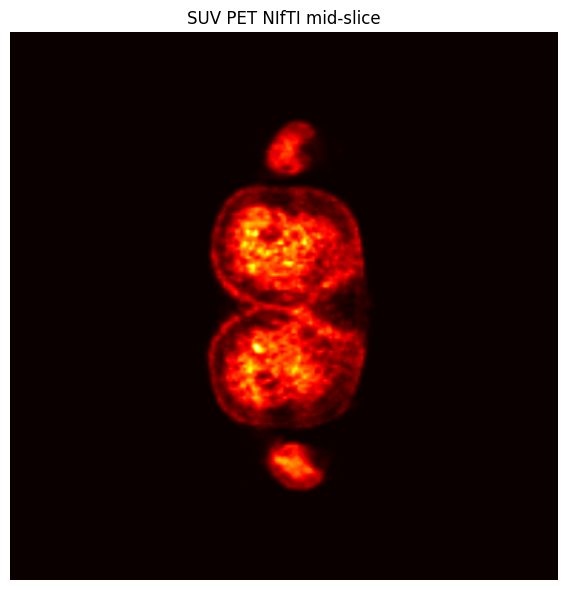

In [6]:
import matplotlib.pyplot as plt

pet_series_dir = Path('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/dicoms_rewrite/27823719/27823719_pt_2')
pet_nii_path = Path('/gpfs/data/mayerhoeferlab/projects/myeloma/process_dicoms_for_mars/nibabel_rewrite_for_autopet3_flat/27823719_0001.nii.gz')

pet_paths = sorted(pet_series_dir.glob('*.dcm'))
pet_header = pydicom.dcmread(str(pet_paths[0]), stop_before_pixels=True)
pet_volume = nib.load(str(pet_nii_path)).get_fdata(dtype=np.float32)

print('PET units:', getattr(pet_header, 'Units', None))
print('PET SUV factor:', _pet_suv_factor_from_dicom_series(pet_series_dir))
print('PET NIfTI shape:', pet_volume.shape)
print('PET NIfTI min/max/mean:', float(pet_volume.min()), float(pet_volume.max()), float(pet_volume.mean()))

pet_mid = pet_volume[:, :, pet_volume.shape[2] // 2]
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(pet_mid, cmap='hot', origin='lower')
ax.set_title('SUV PET NIfTI mid-slice')
ax.set_axis_off()
plt.tight_layout()
plt.show()
